# Project title
## MSE course EVA_CE4IB 2026

Authors: Drigatti Alessio, Zurbrügg Milena



[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/drigaa/rEVA_CE4IB/HEAD?urlpath=%2Fdoc%2Ftree%2Fcasestudy.ipynb)

## Project Overview
The objective of this project is to simulate the thermal dynamics of two rooms located at the corner of a building. Figure 1 illustrates the floor plan of the area under consideration including the relevant measurements. Each room has a hight of 3 m.

![thermal-network](images/Room_Plan.png)

Figure 1: Floor Plan of the considered area.

The two grey areas represent the rooms considered in this project. Room 5, located on the right-hand side, is situated at the corner of the building and therefore has two external façades. One external side consists of an insulated concrete wall (orange), while the other contains a window (blue). Room 5 is connected to Room 9 through a non-insulated concrete wall (orange).

Room 9 is adjacent to the exterior through a single window (blue). The regions highlighted in red are assumed to have no influence on the thermal behavior of the rooms, as they are considered to be exposed to the same boundary conditions as the indoor environment and are therefore neglected in the analysis.




## Thermal Network

The thermal behaviour of the two rooms is represented by a lumped-parameter thermal network based on thermal resistances, thermal capacitances, temperature sources, and heat flow sources. Figure 2 illustrates the complete network of the considered area.

![thermal-network](images/Screenshot%202026-10-29%20093356.png)

Figure 2: Thermal circuit for the considered area shown in Figure 1.

The outdoor temperature *T<sub>0</sub>* acts as the external boundary condition for all building envelope components. Room air temperatures are represented by nodes 5 and 9, corresponding to Rooms 5 and 9 in the floor plan, respectively. Each room is connected to a temperature source *T<sub>i,sp</sub>*, representing the HVAC control system that maintains the indoor air temperature at the prescribed setpoint. The conductances in branches 10 and 11 model the heating or cooling power required to keep the rooms at their setpoint temperatures.

### Exterior Corner Wall of Room 5

The insulated exterior wall of Room 5 is shown in Figure 2 in orange, going from node 0 to node 4. Heat is transferred from the outdoor environment through an external convective resistance (branch 0) into the wall structure. Solar radiation absorbed by the outer wall surface is represented by the heat flow source *Φ<sub>0</sub>*, which is connected to node 0.

The wall itself consists of concrete and insulation layers discretized into four conductive branches (1-4). Thermal masses are assigned to nodes 1 and 3, representing the heat storage capacity of the wall materials. Heat is finally transferred to the room air through an internal convective resistance (branch 5), connecting the wall to the indoor air node of Room 5 (node 5).

### Internal Wall Between Rooms

The separating wall between Rooms 5 and 9 consists of non-insulated concrete and is represented by nodes 6 to 8. Convective heat transfer occurs on both wall surfaces (branches 6 and 9), while conductive heat transport through the concrete is described by branches 7 and 8. A thermal capacitance is assigned to node 7 to account for heat storage within the wall.

This wall establishes thermal coupling between the two rooms, allowing heat transfer whenever a temperature difference exists between nodes 5 and 9.

### Room Air Nodes

The indoor air of each room is represented by a thermal capacitance connected to nodes 5 and 9. These capacitances describe the thermal storage capacity of the room air and the interior contents lumped into a single node.

Both rooms are subjected to internal heat gains *Q<sub>aux</sub>*, representing occupants, lighting, electrical devices, and other internal heat sources. These gains are directly added to the respective room air nodes.

Additionally, solar radiation transmitted through the windows and absorbed within the rooms is represented by the heat flow source *Φ<sub>i</sub>*.

### Windows

Each room contains a window exposed to the outdoor environment. Heat transfer through the windows is represented by branches 12 and 13, connecting the outdoor temperature source *T<sub>0</sub>* directly to the room air nodes through an equivalent thermal conductance.

## Defining parameters

## Defining the matrixes and vectors

The thermal network is described by the branch heat-flow equation

\begin{equation}
q =  G(-A*θ + b),
\end{equation}

where q is the vector of heat flows through the network branches,

\begin{equation}
q =
\begin{bmatrix}
q_0 & q_1 & q_2 & q_3 & q_4 & q_5 &
q_6 & q_7 & q_8 & q_9 & q_{10} & q_{11} & q_{12} & q_{13}
\end{bmatrix}
^{T}.
\end{equation}

The temperature state vector

\begin{equation}
θ =
\begin{bmatrix}
\theta_0 & \theta_1 & \theta_2 & \theta_3 &
\theta_4 & \theta_5 & \theta_6 & \theta_7 & \theta_8 & \theta_9
\end{bmatrix}^{T}
\end{equation}

contains the temperatures of the eight thermal nodes.

The incidence matrix defines the connectivity between the 14 heat-flow branches and the 10 temperature nodes. A value of $1$ indicates if the flow goes into the node, while $-1$ indicates if it gets out of the node.
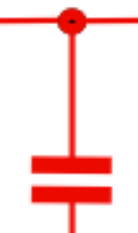

The diagonal conductance matrix contains the thermal conductances of all branches.

The boundary-condition vector

\begin{equation}
b =
\begin{bmatrix}
T_o & 0 & 0 & 0 & 0 & 0 & 0 & 0 &
0 & 0 & T_{isp} & T_{isp} & T_o & T_o
\end{bmatrix}^{T}
\end{equation}

introduces prescribed temperatures into the network, where $T_o$ denotes the outdoor temperature and $T_{isp}$ the indoor temperature setpoint.

The dynamic behaviour of the system is represented by the capacitance matrix

\begin{equation}
\mathbf C =
\operatorname{diag}
(0, C_1, 0, C_3, 0, C_5, 0, C_7, 0, C_9),
\end{equation}

which contains the thermal capacities associated with the storage nodes of the network. Nodes with zero entries are assumed to have negligible thermal storage.

Finally, the source vector

\begin{equation}
f =
\begin{bmatrix}
\Phi_o &
0 &
0 &
0 &
\Phi_i &
\dot Q_{aux} &
\Phi_i &
0 &
\Phi_i &
\dot Q_a &
\end{bmatrix}^{T}
\end{equation}

contains all external heat inputs. Here, $\Phi_o$ represents solar and environmental heat gains, $\Phi_i$ the internal heat gains, $\dot Q_a$ the ventilation or air-flow heat exchange rate, and $\Phi_a$ the heat supplied by the HVAC system.

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from dm4bem import read_epw, sol_rad_tilt_surf

In [ ]:
filename = Path("weather_data/Hombrechtikon/CHE_ZH_Hombrechtikom.068510_TMYx.2011-2025.epw")
data, meta = read_epw(filename, coerce_year=None)

## Connect this to data
T_0 = 10

In [ ]:
data.value_counts(subset=["year", "month"])

In [ ]:
weather_data = data[["temp_air", "dir_n_rad", "dif_h_rad"]]

In [ ]:
# radiative properties
ε_wLW = 0.85    # long wave emmisivity: wall surface (concrete)
ε_gLW = 0.90    # long wave emmisivity: glass pyrex
α_wSW = 0.25    # short wave absortivity: white smooth surface
α_gSW = 0.38    # short wave absortivity: reflective blue glass
τ_gSW = 0.30    # short wave transmitance: reflective blue glass

sbc = 5.67e-8

In [ ]:
air = {
    'Density': 1.2,
    'Specific heat': 1000
}

In [ ]:
l = 3

concrete = {
    'Conductivity': 1.400,
    'Density': 2300.0,
    'Specific heat': 880,
    'Width': 0.15,
    'Surface': l**2
}

insulation = {
    'Conductivity': 0.040,
    'Density': 16.0,
    'Specific heat': 1210,
    'Width': 0.25,
    'Surface': l**2
}

glass = {
    'U-Value': 0.6,
    'Surface': l**2
}

wall = pd.DataFrame.from_dict(
    {
        'Layer_out': insulation,
        'Layer_in': concrete,
        'window': glass
    },
    orient='index')

wall

In [ ]:
# convection coefficients, W/(m²·K)
h = pd.DataFrame([{'in': 4., 'out': 10.}], index=['h'])
h

In [ ]:
## P-controler gain
Kp = 0
Ti_sp = 30

In [ ]:
number_of_nodes = 10
number_of_branches = 14
G_diag = np.zeros(number_of_branches)

G_diag[[1, 2]] = (wall["Conductivity"] / (wall["Width"] / 2) * wall["Surface"]).Layer_out
G_diag[[3, 4, 7 ,8]] =  (wall["Conductivity"] / (wall["Width"] / 2) * wall["Surface"]).Layer_in

G_diag[[0]] = h['out'] * wall["Surface"].Layer_out
G_diag[[5, 6, 9]] = h['in'] * wall["Surface"].Layer_in

G_diag[[12, 13]] = (wall['U-Value'] * wall["Surface"]).window

G_diag[[10, 11]] = Kp

G = np.diag(G_diag)

In [ ]:
C_diag = np.zeros(number_of_nodes)

In [ ]:
C_diag[1] = (wall['Width'] * wall['Surface'] * wall['Density'] * wall["Specific heat"]).Layer_out
C_diag[[3, 7]] = (wall['Width'] * wall['Surface'] * wall['Density'] * wall["Specific heat"]).Layer_in
C_diag[[5, 9]] = air["Density"] * l**3 * air["Specific heat"]
C = np.diag(C_diag)
C

In [ ]:
A = np.zeros((14, 10))

In [ ]:
A[0, 0] = 1
A[1, 0], A[1, 1] = -1, 1
A[2, 1], A[2, 2] = -1, 1
A[3, 2], A[3, 3] = -1, 1
A[4, 3], A[4, 4] = -1, 1
A[5, 4], A[5, 5] = -1, 1
A[6, 6], A[6, 5] = -1, 1
A[7, 7], A[7, 6] = -1, 1
A[8, 8], A[8, 7] = -1, 1
A[9, 9], A[9, 8] = -1, 1
A[10, 9] = 1
A[11, 5] = 1
A[12, 9] = 1
A[13, 5] = 1

In [ ]:
b = np.zeros(number_of_branches)
b[[0, 12, 13]] = T_0
b[[10, 11]] = Ti_sp

In [ ]:
f = np.zeros(number_of_nodes)

In [ ]:
temp_steady_state = np.linalg.inv(A.T @ G @ A) @ (A.T @ G @ b + f)
pd.Series(temp_steady_state)